# Routing comparison with the Lin et al. spectral mapper

This notebook compares SABRE, Trivial, FOM, SAM, and the one-dimensional Lin et al. mapper in `spectral_mapping_linetal.py` on random-regular and Barab?si?Albert MaxCut graphs. It reports routed SWAP count, optimized two-qubit gate count and depth, plus compilation time.

Run the small smoke example immediately after imports before starting the parameter sweep. It uses an eight-qubit circuit and caps hardware-path search at 5,000 DFS expansions. The benchmark helpers and plotting code are defined in this notebook; the existing `helper_functions.py` and `implementation.py` are imported read-only for the baseline mapping/routing algorithms.


## Imports and backend

In [33]:
from pathlib import Path
import random
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import QAOAAnsatz, RZZGate
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh
from tqdm.auto import tqdm

# # Make imports work whether Jupyter was launched in the repo root or submissions/.
# _submission_candidates = [Path.cwd(), Path.cwd() / 'submissions']
# SUBMISSIONS_DIR = next(
#     (path.resolve() for path in _submission_candidates
#      if (path / 'implementation.py').is_file()),
#     None,
# )
# if SUBMISSIONS_DIR is None:
#     raise FileNotFoundError(
#         'Could not find submissions/implementation.py. Open this notebook from the repository.'
#     )
# if str(SUBMISSIONS_DIR) not in sys.path:
    # sys.path.insert(0, str(SUBMISSIONS_DIR))

from implementation import (
    custom_routed_circuit,
    fiedler_ordered_mapping,
    optimized_without_layout_routing,
    sabre_layout,
    spectral_assignment_mapping,
)
from spectral_mapping_linetal import (
    route_circuit_on_heavyhex_path,
    transpile_mapped_result,
)

import warnings
warnings.filterwarnings('ignore')

backend = FakeMarrakesh()
print(f'Backend: {backend.name}, physical qubits: {backend.num_qubits}')


Backend: fake_marrakesh, physical qubits: 156


## Notebook-local helpers

These helpers replace the corresponding comparison/plotting helpers from `helper_functions.py`, with an added Lin et al. route. The Lin et al. mapper performs layout selection and routing in one call, so its time is recorded under `routing_time`; `total_compilation_time` is the apples-to-apples time chart.


In [66]:
def barabasi_albert_graph(n, m, seed=None):
    """Build a deterministic BA graph using the comparison notebook's generator."""
    if m < 1 or m >= n:
        raise ValueError('Require 1 <= m < n.')
    rng = random.Random(seed)
    graph = nx.Graph()
    if m == 1:
        graph.add_node(0)
        node_list = [0]
        start = 1
    else:
        graph.add_nodes_from(range(m))
        for i in range(m):
            for j in range(i + 1, m):
                graph.add_edge(i, j)
        node_list = [i for i in range(m) for _ in range(m - 1)]
        start = m
    for new_node in range(start, n):
        targets = set()
        while len(targets) < m:
            targets.add(rng.choice(node_list))
        for target in targets:
            graph.add_edge(new_node, target)
            node_list.extend((target, new_node))
    return graph


def build_max_cut_paulis(graph):
    """Create the reversed-label Pauli terms used by the existing QAOA helper."""
    n = graph.number_of_nodes()
    terms = []
    for u, v, data in graph.edges(data=True):
        paulis = ['I'] * n
        paulis[u] = 'Z'
        paulis[v] = 'Z'
        terms.append((''.join(paulis)[::-1], float(data.get('weight', 1.0))))
    return terms


def gen_qaoa_circuit(graph, reps=1):
    """Create a measured QAOA MaxCut ansatz for the given graph."""
    cost = SparsePauliOp.from_list(build_max_cut_paulis(graph))
    circuit = QAOAAnsatz(cost_operator=cost, reps=reps)
    circuit.measure_all()
    return circuit


def custom_qaoa_ansatz(graph, layout, coupling_map, reps=1):
    """Create the mapping-aware MaxCut ansatz used for FOM and SAM."""
    n = graph.number_of_nodes()
    circuit = QuantumCircuit(n)
    gammas = ParameterVector('gamma', reps)
    betas = ParameterVector('beta', reps)
    circuit.h(range(n))

    coupling_graph = nx.Graph()
    coupling_graph.add_edges_from(coupling_map)
    edge_info = []
    for u, v in graph.edges():
        try:
            distance = nx.shortest_path_length(coupling_graph, layout[u], layout[v])
        except nx.NetworkXNoPath:
            distance = float('inf')
        edge_info.append((u, v, distance))
    edge_info.sort(key=lambda item: item[2])

    for rep in range(reps):
        for u, v, _ in edge_info:
            circuit.append(RZZGate(2 * gammas[rep]), [u, v])
        for qubit in range(n):
            circuit.rx(2 * betas[rep], qubit)
    circuit.measure_all()
    return circuit


def timed_call(function, *args, **kwargs):
    """Return (function result, elapsed wall-clock seconds)."""
    start = perf_counter()
    result = function(*args, **kwargs)
    return result, perf_counter() - start


def circuit_metrics(routed_circuit, optimized_circuit, swap_count=None):
    """Collect swap count before optimization and quality metrics after it."""
    if swap_count is None:
        swap_count = routed_circuit.count_ops().get('swap', 0)
    two_qubit_gates = sum(
        instruction.operation.num_qubits == 2
        for instruction in optimized_circuit.data
    )
    return {
        'swaps': int(swap_count),
        'two_qubit_gates': int(two_qubit_gates),
        'circuit_depth': int(optimized_circuit.depth() or 0),
    }


METHODS = ['SABRE', 'Trivial', 'FOM', 'SAM2', 'Lin et al.']
QUALITY_METRICS = ['swaps', 'two_qubit_gates', 'circuit_depth']
TIME_METRICS = [
    'mapping_time',
    'circuit_generation_time',
    'routing_time',
    'optimization_time',
    'total_compilation_time',
]
METHOD_COLORS = {
    'SABRE': '#E69F00',
    'Trivial': '#56B4E9',
    'FOM': '#009E73',
    'SAM2': '#D55E00',
    'SAM3': '#0072B2',
    'SAM4': '#CC79A7',
    'Lin et al.': '#000000',
}


def benchmark_one_graph(
    graph,
    backend,
    *,
    k_list=(2, 3, 4),
    reps=1,
    opt_level=1,
    average_over=1,
    noise_aware=True,
    max_path_expansions=5_000,
):
    """Compare every method on one fixed graph and summarize repeated runs."""
    if average_over < 1:
        raise ValueError('average_over must be at least one.')
    methods = ['SABRE', 'Trivial', 'FOM'] + [f'SAM{k}' for k in k_list] + ['Lin et al.']
    metric_samples = {
        metric: {method: [] for method in methods}
        for metric in QUALITY_METRICS + TIME_METRICS
    }

    for _ in range(average_over):
        generic, generic_generation_time = timed_call(gen_qaoa_circuit, graph, reps)
        generic, transpile_time = timed_call(
            transpile, generic, basis_gates=backend.basis_gates, seed_transpiler=0
        )
        generic_generation_time += transpile_time

        # Initial layouts: FOM, SAM, Trivial, and SABRE use the same strategies
        # as comparison_plots_revision.ipynb.
        mappings = {'Trivial': {i: i for i in range(graph.number_of_nodes())}}
        mappings['FOM'], fom_mapping_time = timed_call(
            fiedler_ordered_mapping,
            graph,
            backend,
            noise_aware=noise_aware,
            normalized=False,
        )
        mapping_times = {
            'Trivial': 0.0,
            'FOM': fom_mapping_time,
        }
        for k in k_list:
            method = f'SAM{k}'
            mappings[method], mapping_times[method] = timed_call(
                spectral_assignment_mapping,
                graph,
                backend,
                k=k,
                noise_aware=noise_aware,
                normalized=True,
            )
        mappings['SABRE'], mapping_times['SABRE'] = timed_call(
            sabre_layout, generic, backend
        )

        # Circuit construction and basis translation are included in generation time.
        circuits = {'Trivial': generic, 'SABRE': generic}
        generation_times = {
            'Trivial': generic_generation_time,
            'SABRE': generic_generation_time,
            'Lin et al.': generic_generation_time,
        }
        for method in ['FOM'] + [f'SAM{k}' for k in k_list]:
            initial, elapsed = timed_call(
                custom_qaoa_ansatz,
                graph,
                mappings[method],
                backend.coupling_map,
                reps,
            )
            circuits[method], translation_time = timed_call(
                transpile, initial,
                basis_gates=backend.basis_gates,
                seed_transpiler=0,
            )
            generation_times[method] = elapsed + translation_time

        for method in ['SABRE', 'Trivial', 'FOM'] + [f'SAM{k}' for k in k_list]:
            routed, routing_time = timed_call(
                custom_routed_circuit,
                circuits[method],
                mappings[method],
                backend,
                opt_level=opt_level,
            )
            optimized, optimization_time = timed_call(
                optimized_without_layout_routing,
                routed,
                backend,
                opt_level=opt_level,
            )
            values = circuit_metrics(routed, optimized)
            for metric, value in values.items():
                metric_samples[metric][method].append(value)
            metric_samples['mapping_time'][method].append(mapping_times[method])
            metric_samples['circuit_generation_time'][method].append(
                generation_times[method]
            )
            metric_samples['routing_time'][method].append(routing_time)
            metric_samples['optimization_time'][method].append(optimization_time)
            metric_samples['total_compilation_time'][method].append(
                mapping_times[method] + generation_times[method]
                + routing_time + optimization_time
            )

        # Lin et al. jointly selects a layout and routes the circuit. Its complete
        # mapper run is therefore timed as routing; mapping_time is zero by design.
        spectral_result, routing_time = timed_call(
            route_circuit_on_heavyhex_path,
            generic,
            backend,
            max_path_expansions=max_path_expansions,
        )
        optimized, optimization_time = timed_call(
            transpile_mapped_result,
            spectral_result,
            backend,
            optimization_level=opt_level,
            seed_transpiler=0,
        )
        values = circuit_metrics(
            spectral_result.circuit,
            optimized,
            swap_count=spectral_result.swap_count,
        )
        method = 'Lin et al.'
        for metric, value in values.items():
            metric_samples[metric][method].append(value)
        metric_samples['mapping_time'][method].append(0.0)
        metric_samples['circuit_generation_time'][method].append(
            generation_times[method]
        )
        metric_samples['routing_time'][method].append(routing_time)
        metric_samples['optimization_time'][method].append(optimization_time)
        metric_samples['total_compilation_time'][method].append(
            generation_times[method] + routing_time + optimization_time
        )

    def summarize(metric):
        return {
            'means': {
                method: float(np.mean(metric_samples[metric][method]))
                for method in methods
            },
            'stddevs': {
                method: float(np.std(metric_samples[metric][method]))
                for method in methods
            },
            'medians': {
                method: float(np.median(metric_samples[metric][method]))
                for method in methods
            },
        }

    return {
        'quality': {metric: summarize(metric) for metric in QUALITY_METRICS},
        'times': {metric: summarize(metric) for metric in TIME_METRICS},
        'methods': methods,
    }


def make_benchmark_graph(graph_type, n, param, seed=0):
    if graph_type == 'reg':
        return nx.random_regular_graph(n=n, d=param, seed=seed)
    if graph_type == 'ba':
        return barabasi_albert_graph(n=n, m=param, seed=seed)
    raise ValueError("graph_type must be either 'reg' or 'ba'.")


def run_comparison(
    backend,
    *,
    graph_type,
    params,
    node_list,
    k_list=(2, 3, 4),
    reps=1,
    opt_level=1,
    average_over=1,
    noise_aware=True,
):
    """Return metric statistics indexed by graph parameter and graph size."""
    results = {}
    for param in params:
        per_param = {}
        for n in tqdm(node_list, desc=f'{graph_type}, parameter={param}'):
            graph = make_benchmark_graph(graph_type, n, param, seed=0)
            per_param[n] = benchmark_one_graph(
                graph,
                backend,
                k_list=k_list,
                reps=reps,
                opt_level=opt_level,
                average_over=average_over,
                noise_aware=noise_aware,
            )
        results[param] = per_param
    return results


def metric_table(results, node_list, params, group, metric, methods=METHODS):
    """Create a tidy mean ? standard-deviation table."""
    rows = []
    for param in params:
        for n in node_list:
            if n not in results[param]:
                continue
            stats = results[param][n][group][metric]
            row = {'Parameter': param, 'Qubits': n}
            for method in methods:
                mean = stats['means'][method]
                std = stats['stddevs'][method]
                row[method] = f'{mean:.3f} ? {std:.3f}'
            rows.append(row)
    return pd.DataFrame(rows)


def plot_metric_results(results, node_list, params, group, metric, ylabel=None, title_prefix=''):
    """Plot means and one-standard-deviation bands for all comparison methods."""
    ylabel = ylabel or metric.replace('_', ' ').title()
    for param in params:
        fig, ax = plt.subplots(figsize=(9, 6))
        for method in METHODS:
            xs, means, stds = [], [], []
            for n in node_list:
                if n not in results[param]:
                    continue
                stats = results[param][n][group][metric]
                xs.append(n)
                means.append(stats['means'][method])
                stds.append(stats['stddevs'][method])
            if not xs:
                continue
            means = np.asarray(means)
            stds = np.asarray(stds)
            ax.plot(xs, means, label=method, color=METHOD_COLORS.get(method), linewidth=2)
            ax.fill_between(
                xs, np.maximum(0, means - stds), means + stds,
                color=METHOD_COLORS.get(method), alpha=0.16,
            )
        ax.set_xlabel('Number of Nodes', fontsize=18)
        ax.set_ylabel('SWAPs', fontsize=18)
        # ax.set_title(f'{title_prefix} (parameter = {param})' if title_prefix else f'{metric} (parameter = {param})')
        ax.set_xlim(left=0)
        ax.set_ylim(bottom=0)
        # ax.set_xticks(fontsize=14)
        # ax.set_yticks(fontsize=14)

        #increase ticks size
        ax.tick_params(axis='both', which='major', labelsize=14)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=14)
        fig.tight_layout()
        plt.show()



## Smoke example: eight-qubit circuit

This intentionally runs before the full sweep. It exercises circuit translation, automatic hardware-path extraction, scheduling, SWAP insertion, and output-circuit construction. The small circuit and DFS expansion limit keep the example bounded; the wall-time assertion flags a slow run on the current machine.


In [18]:
smoke_graph = nx.cycle_graph(20)
smoke_circuit = gen_qaoa_circuit(smoke_graph, reps=1)
smoke_circuit = transpile(
    smoke_circuit,
    basis_gates=backend.basis_gates,
    seed_transpiler=0,
)

smoke_start = perf_counter()
smoke_result = route_circuit_on_heavyhex_path(
    smoke_circuit,
    backend,
    max_path_expansions=5_000,
)
smoke_elapsed = perf_counter() - smoke_start

assert len(smoke_result.path) == smoke_circuit.num_qubits == 20
assert smoke_result.circuit.num_qubits == backend.num_qubits
_coupling_edges = {tuple(sorted(edge)) for edge in backend.coupling_map.get_edges()}
assert all(
    tuple(sorted((u, v))) in _coupling_edges
    for u, v in smoke_result.swap_sequence
)
assert smoke_elapsed < 30.0, (
    f'The eight-qubit spectral routing example took {smoke_elapsed:.1f}s '
    '(limit: 30s).'
)
print(
    f'Lin et al. smoke example passed: {smoke_result.swap_count} SWAPs, '
    f'{smoke_elapsed:.2f}s, path length {len(smoke_result.path)}.'
)


Lin et al. smoke example passed: 57 SWAPs, 0.02s, path length 20.


In [19]:
smoke_result.circuit.draw('mpl', fold=-1)

## Experiment configuration

The defaults below are a quick comparison sweep. To match the larger sweep in `comparison_plots_revision.ipynb`, increase `nodes_reg`/`nodes_ba`, add the remaining graph parameters, and raise `average_over` after the smoke example passes.


In [32]:
k_list = [2, 3, 4]
average_over = 2
reps = 1
opt_level = 1
noise_aware = True

nodes_reg = [10, 20, 30, 40]
params_reg = [3, 4]
nodes_ba = [10, 20, 30, 40]
params_ba = [2, 3]


## Collect metrics

In [21]:
results_reg = run_comparison(
    backend,
    graph_type='reg',
    params=params_reg,
    node_list=nodes_reg,
    k_list=k_list,
    reps=reps,
    opt_level=opt_level,
    average_over=average_over,
    noise_aware=noise_aware,
)

results_ba = run_comparison(
    backend,
    graph_type='ba',
    params=params_ba,
    node_list=nodes_ba,
    k_list=k_list,
    reps=reps,
    opt_level=opt_level,
    average_over=average_over,
    noise_aware=noise_aware,
)


ba, parameter=3: 100%|██████████| 4/4 [00:02<00:00,  1.50it/s]


## Tables

In [22]:
for graph_name, results, nodes, params in [
    ('Random regular graphs', results_reg, nodes_reg, params_reg),
    ('Barab?si?Albert graphs', results_ba, nodes_ba, params_ba),
]:
    print(f'\n{graph_name}')
    for metric, label in [
        ('swaps', 'Routed SWAP count'),
        ('two_qubit_gates', 'Optimized two-qubit gate count'),
        ('circuit_depth', 'Optimized circuit depth'),
    ]:
        print(f'\n{label}')
        display(metric_table(results, nodes, params, 'quality', metric))
    for metric, label in [
        ('mapping_time', 'Mapping time (seconds)'),
        ('circuit_generation_time', 'Circuit generation time (seconds)'),
        ('routing_time', 'Routing time (seconds)'),
        ('optimization_time', 'Optimization time (seconds)'),
        ('total_compilation_time', 'Total compilation time (seconds)'),
    ]:
        print(f'\n{label}')
        display(metric_table(results, nodes, params, 'times', metric))



Random regular graphs

Routed SWAP count


,Parameter,Qubits,SABRE,Trivial,FOM,SAM2,SAM3,SAM4,Lin et al.
0,3,10,10.000 ? 0.000,26.000 ? 0.000,10.000 ? 0.000,12.000 ? 0.000,13.000 ? 0.000,14.000 ? 0.000,14.000 ? 0.000
1,3,20,28.000 ? 0.000,112.500 ? 1.500,29.500 ? 0.500,29.000 ? 0.000,33.500 ? 0.500,31.000 ? 0.000,82.000 ? 0.000
2,3,30,68.500 ? 0.500,171.000 ? 5.000,56.500 ? 0.500,50.000 ? 1.000,62.000 ? 0.000,70.000 ? 1.000,237.000 ? 0.000
3,3,40,84.500 ? 0.500,245.000 ? 8.000,107.500 ? 1.500,70.500 ? 0.500,97.000 ? 2.000,104.500 ? 0.500,399.000 ? 0.000
4,4,10,15.000 ? 0.000,32.000 ? 0.000,17.000 ? 0.000,20.000 ? 0.000,15.000 ? 0.000,14.000 ? 0.000,45.000 ? 0.000
5,4,20,64.000 ? 2.000,127.000 ? 5.000,61.500 ? 0.500,46.000 ? 1.000,50.500 ? 0.500,49.000 ? 0.000,238.000 ? 0.000
6,4,30,113.000 ? 2.000,226.500 ? 1.500,102.000 ? 1.000,111.000 ? 2.000,98.500 ? 3.500,100.000 ? 0.000,681.000 ? 0.000
7,4,40,201.500 ? 0.500,324.000 ? 6.000,164.500 ? 1.500,160.000 ? 4.000,166.500 ? 0.500,144.500 ? 0.500,948.000 ? 0.000



Optimized two-qubit gate count


,Parameter,Qubits,SABRE,Trivial,FOM,SAM2,SAM3,SAM4,Lin et al.
0,3,10,60.000 ? 0.000,108.000 ? 0.000,60.000 ? 0.000,66.000 ? 0.000,69.000 ? 0.000,72.000 ? 0.000,72.000 ? 0.000
1,3,20,144.000 ? 0.000,397.500 ? 4.500,148.500 ? 1.500,147.000 ? 0.000,160.500 ? 1.500,153.000 ? 0.000,304.000 ? 0.000
2,3,30,295.500 ? 1.500,603.000 ? 15.000,259.500 ? 1.500,240.000 ? 3.000,276.000 ? 0.000,300.000 ? 3.000,797.000 ? 0.000
3,3,40,373.500 ? 1.500,855.000 ? 24.000,442.500 ? 4.500,331.500 ? 1.500,411.000 ? 6.000,433.500 ? 1.500,1303.000 ? 0.000
4,4,10,85.000 ? 0.000,136.000 ? 0.000,91.000 ? 0.000,100.000 ? 0.000,85.000 ? 0.000,82.000 ? 0.000,161.000 ? 0.000
5,4,20,272.000 ? 6.000,461.000 ? 15.000,264.500 ? 1.500,218.000 ? 3.000,231.500 ? 1.500,227.000 ? 0.000,794.000 ? 0.000
6,4,30,459.000 ? 6.000,799.500 ? 4.500,426.000 ? 3.000,453.000 ? 6.000,415.500 ? 10.500,420.000 ? 0.000,2129.000 ? 0.000
7,4,40,764.500 ? 1.500,1132.000 ? 18.000,653.500 ? 4.500,640.000 ? 12.000,659.500 ? 1.500,593.500 ? 1.500,2982.000 ? 0.000



Optimized circuit depth


,Parameter,Qubits,SABRE,Trivial,FOM,SAM2,SAM3,SAM4,Lin et al.
0,3,10,90.000 ? 0.000,155.000 ? 8.000,72.000 ? 5.000,103.000 ? 0.000,96.000 ? 3.000,98.000 ? 0.000,102.000 ? 0.000
1,3,20,175.000 ? 0.000,390.500 ? 6.500,128.000 ? 3.000,128.000 ? 0.000,115.000 ? 6.000,178.500 ? 5.500,255.000 ? 0.000
2,3,30,232.000 ? 3.000,443.500 ? 23.500,125.000 ? 4.000,148.500 ? 15.500,169.500 ? 7.500,178.000 ? 13.000,442.000 ? 0.000
3,3,40,224.500 ? 27.500,597.000 ? 1.000,209.000 ? 6.000,145.500 ? 6.500,187.500 ? 34.500,222.000 ? 9.000,483.000 ? 0.000
4,4,10,179.000 ? 0.000,198.500 ? 8.500,134.000 ? 1.000,127.500 ? 2.500,119.500 ? 6.500,111.000 ? 0.000,237.000 ? 0.000
5,4,20,372.000 ? 14.000,493.000 ? 15.000,204.000 ? 22.000,202.000 ? 9.000,162.500 ? 0.500,181.000 ? 6.000,606.000 ? 0.000
6,4,30,392.500 ? 17.500,615.500 ? 4.500,286.000 ? 42.000,258.000 ? 7.000,248.000 ? 21.000,241.500 ? 10.500,986.000 ? 0.000
7,4,40,498.500 ? 2.500,770.500 ? 29.500,333.000 ? 36.000,317.000 ? 42.000,306.500 ? 22.500,275.000 ? 8.000,1416.000 ? 0.000


... (22 outputs left out)


Optimization time (seconds)


,Parameter,Qubits,SABRE,Trivial,FOM,SAM2,SAM3,SAM4,Lin et al.
0,2,10,0.004 ? 0.000,0.005 ? 0.000,0.004 ? 0.000,0.005 ? 0.000,0.004 ? 0.000,0.005 ? 0.000,0.005 ? 0.000
1,2,20,0.005 ? 0.000,0.006 ? 0.000,0.005 ? 0.000,0.005 ? 0.000,0.005 ? 0.000,0.005 ? 0.000,0.009 ? 0.001
2,2,30,0.006 ? 0.000,0.006 ? 0.000,0.006 ? 0.000,0.006 ? 0.000,0.006 ? 0.000,0.006 ? 0.000,0.009 ? 0.000
3,2,40,0.006 ? 0.000,0.007 ? 0.000,0.007 ? 0.000,0.007 ? 0.000,0.006 ? 0.000,0.007 ? 0.000,0.015 ? 0.000
4,3,10,0.005 ? 0.000,0.005 ? 0.000,0.005 ? 0.000,0.005 ? 0.000,0.005 ? 0.000,0.005 ? 0.000,0.006 ? 0.000
5,3,20,0.006 ? 0.000,0.006 ? 0.000,0.006 ? 0.000,0.006 ? 0.000,0.006 ? 0.000,0.006 ? 0.000,0.008 ? 0.000
6,3,30,0.007 ? 0.000,0.007 ? 0.000,0.007 ? 0.000,0.007 ? 0.000,0.007 ? 0.000,0.007 ? 0.000,0.014 ? 0.000
7,3,40,0.007 ? 0.000,0.008 ? 0.000,0.008 ? 0.000,0.010 ? 0.002,0.008 ? 0.001,0.007 ? 0.000,0.017 ? 0.000



Total compilation time (seconds)


,Parameter,Qubits,SABRE,Trivial,FOM,SAM2,SAM3,SAM4,Lin et al.
0,2,10,0.020 ? 0.000,0.015 ? 0.000,0.033 ? 0.000,0.032 ? 0.001,0.032 ? 0.001,0.033 ? 0.001,0.028 ? 0.000
1,2,20,0.025 ? 0.000,0.019 ? 0.001,0.034 ? 0.000,0.034 ? 0.000,0.033 ? 0.001,0.033 ? 0.000,0.098 ? 0.054
2,2,30,0.028 ? 0.000,0.021 ? 0.000,0.036 ? 0.000,0.035 ? 0.000,0.035 ? 0.001,0.035 ? 0.001,0.113 ? 0.052
3,2,40,0.033 ? 0.000,0.025 ? 0.001,0.038 ? 0.001,0.037 ? 0.000,0.037 ? 0.000,0.038 ? 0.000,0.091 ? 0.000
4,3,10,0.021 ? 0.001,0.016 ? 0.000,0.033 ? 0.000,0.032 ? 0.000,0.032 ? 0.001,0.086 ? 0.054,0.030 ? 0.000
5,3,20,0.026 ? 0.001,0.020 ? 0.001,0.036 ? 0.000,0.035 ? 0.000,0.036 ? 0.000,0.090 ? 0.053,0.052 ? 0.000
6,3,30,0.032 ? 0.001,0.025 ? 0.001,0.041 ? 0.000,0.038 ? 0.000,0.038 ? 0.001,0.039 ? 0.001,0.082 ? 0.000
7,3,40,0.039 ? 0.001,0.027 ? 0.001,0.041 ? 0.000,0.043 ? 0.002,0.094 ? 0.054,0.040 ? 0.000,0.124 ? 0.002


## Plots

Random regular graphs


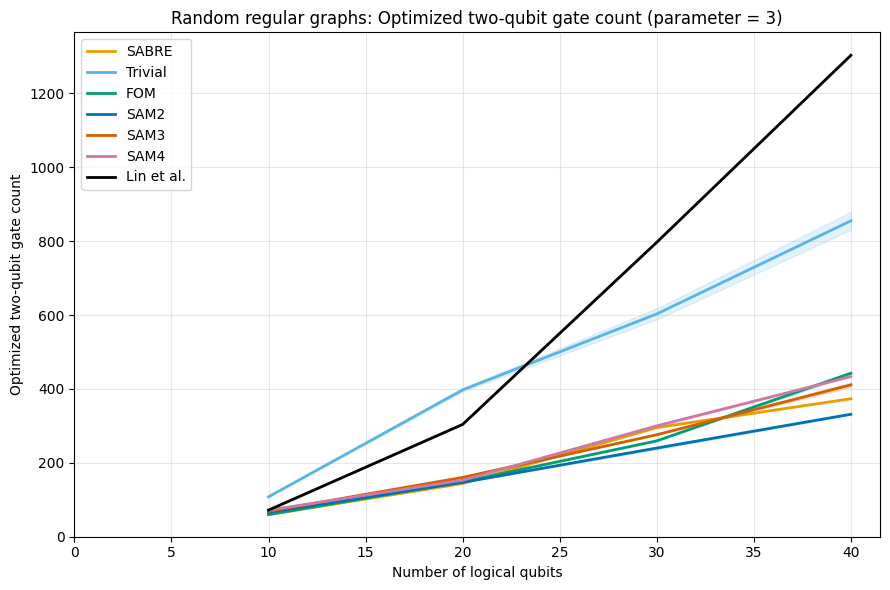

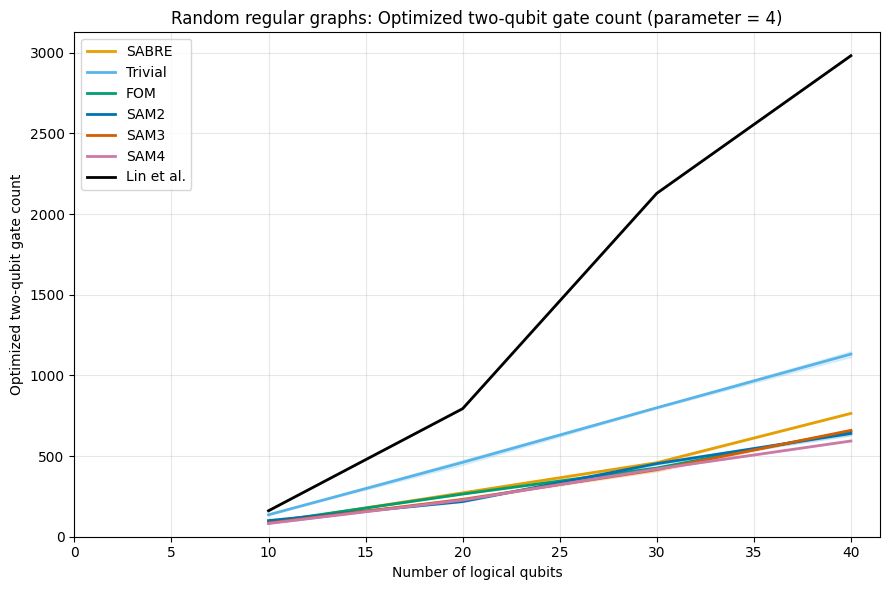

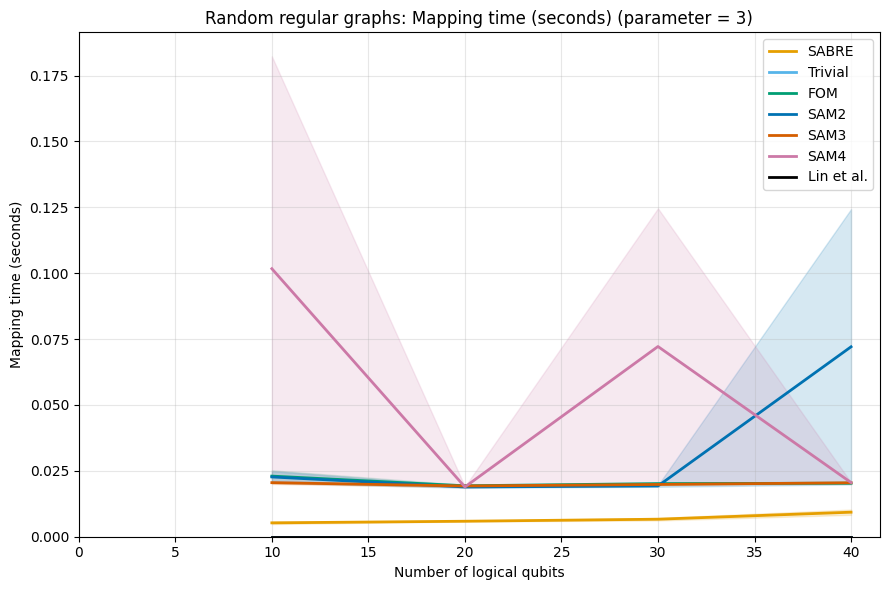

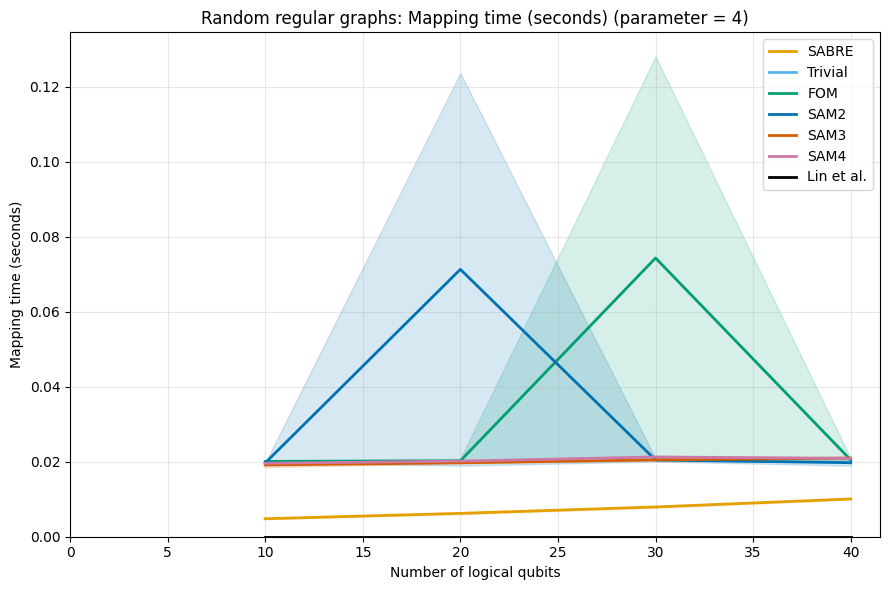

Barab?si?Albert graphs


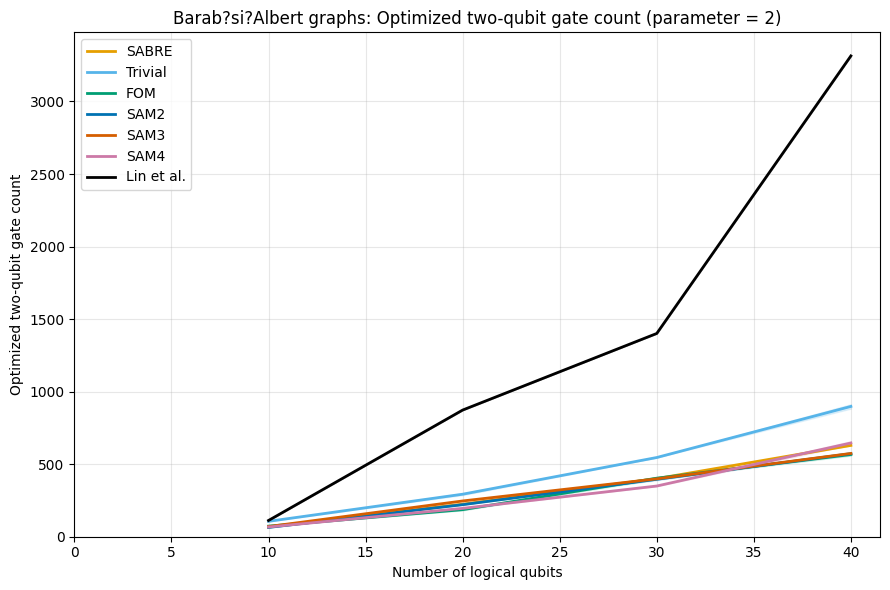

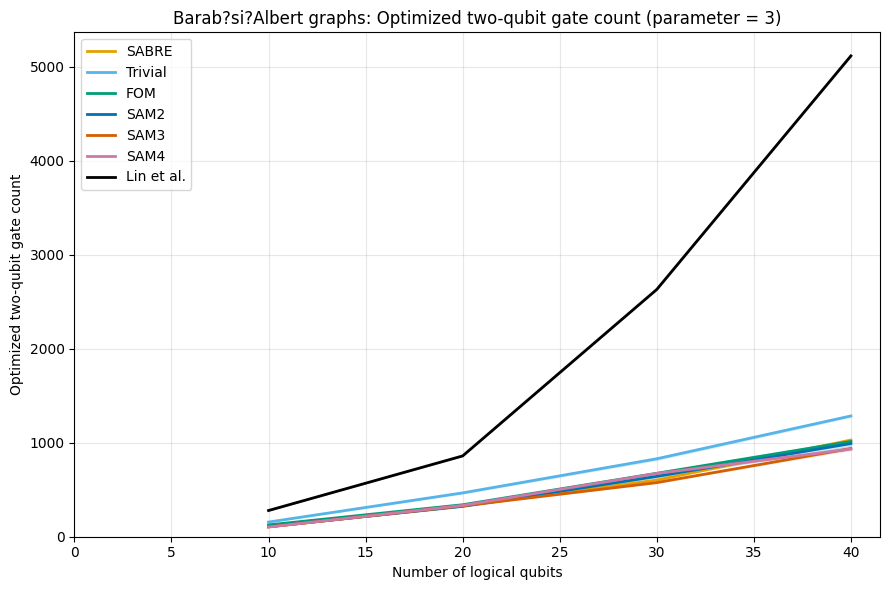

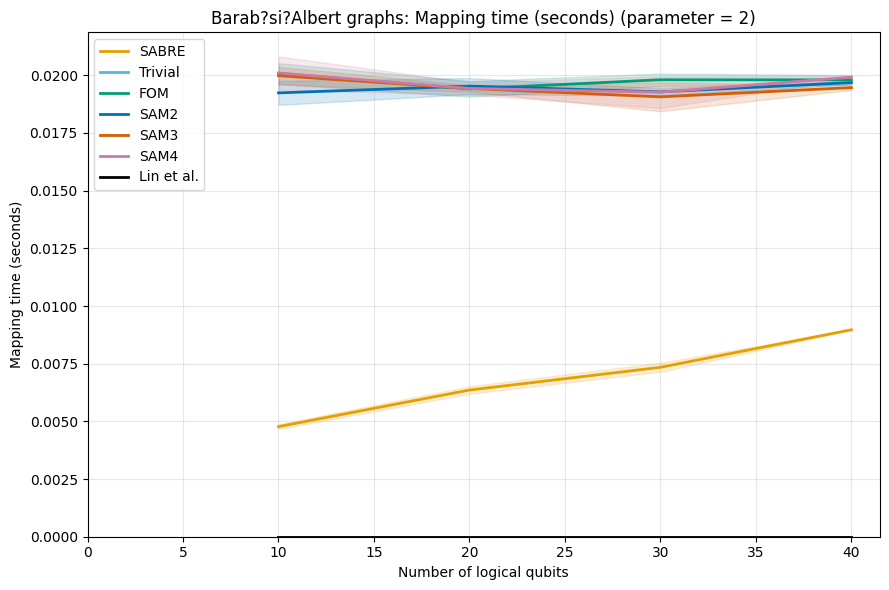

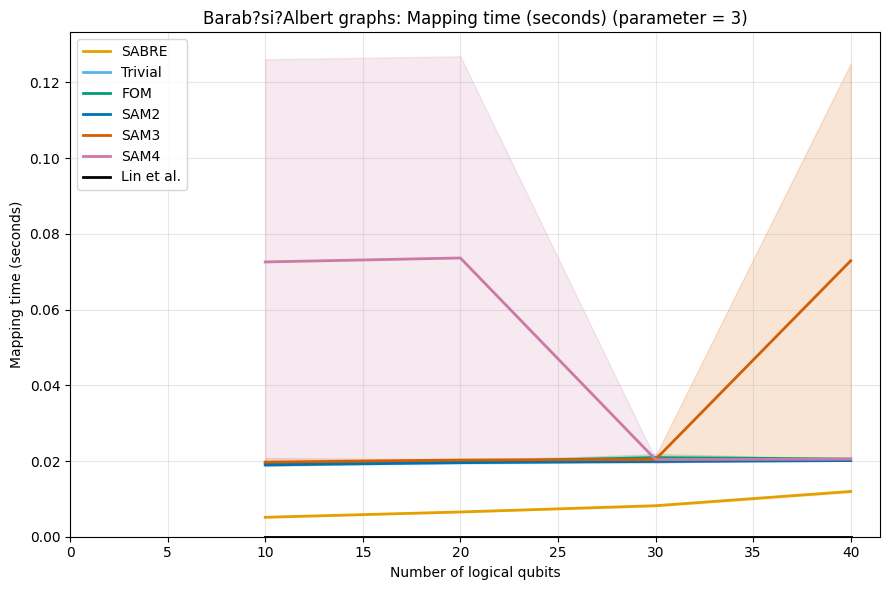

In [ ]:
for graph_name, results, nodes, params in [
    ('Random regular graphs', results_reg, nodes_reg, params_reg),
    ('Barab?si?Albert graphs', results_ba, nodes_ba, params_ba),
]:
    print(graph_name)
    for metric, label in [
        ('swaps', 'SWAP count'),
        # ('two_qubit_gates', 'Optimized two-qubit gate count'),
        # ('circuit_depth', 'Optimized circuit depth'),
    ]:
        plot_metric_results(
            results, nodes, params, 'quality', metric, ylabel=label,
            title_prefix=f'{graph_name}: {label}',
        )
    for metric, label in [
        ('mapping_time', 'Mapping time (seconds)'),
        # ('circuit_generation_time', 'Circuit generation time (seconds)'),
        # ('routing_time', 'Routing time (seconds)'),
        # ('optimization_time', 'Optimization time (seconds)'),
        # ('total_compilation_time', 'Total compilation time (seconds)'),
    ]:
        plot_metric_results(
            results, nodes, params, 'times', metric, ylabel=label,
            title_prefix=f'{graph_name}: {label}',
        )


## LNN comparison on hardware-extracted paths

This section extracts one real hardware path for each logical width, then runs all methods on the corresponding line graph. The selected physical qubit IDs are retained in `lnn_hardware_paths`; the routing pass managers use positions `0..n-1` on an isomorphic line so every method is constrained to the same LNN topology. These gate and depth metrics isolate routing behavior; they do not model calibration differences among the selected physical qubits.


In [36]:
from types import SimpleNamespace
from qiskit.transpiler import CouplingMap
from spectral_mapping_linetal import coupling_graph_from_backend, extract_hardware_path
from implementation import (
    dfs_spanning_tree,
    graph_laplacian_embedding,
    optimal_qubit_assignment,
)


class LNNPathBackend:
    """Small backend adapter exposing an n-qubit bidirectional line topology."""
    def __init__(self, num_qubits, basis_gates, hardware_path):
        if len(hardware_path) != num_qubits:
            raise ValueError('The extracted hardware path must match the circuit width.')
        self.num_qubits = int(num_qubits)
        self.number_of_qubits = int(num_qubits)
        self.basis_gates = list(basis_gates)
        self.hardware_path = list(hardware_path)
        directed_edges = []
        for left in range(num_qubits - 1):
            directed_edges.extend([(left, left + 1), (left + 1, left)])
        self.coupling_map = CouplingMap(directed_edges)

    def configuration(self):
        return SimpleNamespace(
            num_qubits=self.num_qubits,
            coupling_map=self.coupling_map.get_edges(),
        )


def optimize_lnn_circuit(routed_circuit, backend, opt_level=1):
    """Translate/optimize an already-routed line circuit without re-routing."""
    return transpile(
        routed_circuit,
        basis_gates=backend.basis_gates,
        optimization_level=opt_level,
        seed_transpiler=0,
    )


def fiedler_mapping_on_path(graph):
    """Place logical qubits in Fiedler order along the LNN path."""
    logical_tree = dfs_spanning_tree(graph, root=0)
    vector = np.asarray(
        graph_laplacian_embedding(logical_tree, k=1, normalized=False)
    ).reshape(-1)
    logical_order = np.argsort(vector)
    return {int(logical): position for position, logical in enumerate(logical_order)}


def spectral_mapping_on_path(graph, k=2):
    """Match graph and line spectral embeddings, as SAM on an LNN device."""
    n = graph.number_of_nodes()
    logical_embedding = graph_laplacian_embedding(graph, k=k, normalized=True)
    line_embedding = graph_laplacian_embedding(nx.path_graph(n), k=k)
    return optimal_qubit_assignment(
        logical_embedding, line_embedding, nodes=list(range(n))
    )


def benchmark_one_graph_on_lnn(
    graph,
    backend,
    hardware_path,
    *,
    k_list=(2, 3, 4),
    reps=1,
    opt_level=1,
    average_over=1,
):
    """Measure every comparison method on the line corresponding to hardware_path."""
    n = graph.number_of_nodes()
    lnn_backend = LNNPathBackend(n, backend.basis_gates, hardware_path)
    methods = ['SABRE', 'Trivial', 'FOM'] + [f'SAM{k}' for k in k_list] + ['Lin et al.']
    samples = {
        metric: {method: [] for method in methods}
        for metric in QUALITY_METRICS + TIME_METRICS
    }

    for _ in range(average_over):
        generic, generic_time = timed_call(gen_qaoa_circuit, graph, reps)
        generic, elapsed = timed_call(
            transpile, generic, basis_gates=lnn_backend.basis_gates,
            seed_transpiler=0,
        )
        generic_time += elapsed

        mappings = {'Trivial': {i: i for i in range(n)}}
        mappings['FOM'], mapping_fom = timed_call(
            fiedler_mapping_on_path, graph,
        )
        mapping_times = {'Trivial': 0.0, 'FOM': mapping_fom}
        for k in k_list:
            method = f'SAM{k}'
            mappings[method], mapping_times[method] = timed_call(
                spectral_mapping_on_path, graph, k=k,
            )
        mappings['SABRE'], mapping_times['SABRE'] = timed_call(
            sabre_layout, generic, lnn_backend
        )

        circuits = {'Trivial': generic, 'SABRE': generic}
        generation_times = {
            'Trivial': generic_time,
            'SABRE': generic_time,
            'Lin et al.': generic_time,
        }
        for method in ['FOM'] + [f'SAM{k}' for k in k_list]:
            ansatz, ansatz_time = timed_call(
                custom_qaoa_ansatz, graph, mappings[method],
                lnn_backend.coupling_map.get_edges(), reps,
            )
            circuits[method], elapsed = timed_call(
                transpile, ansatz, basis_gates=lnn_backend.basis_gates,
                seed_transpiler=0,
            )
            generation_times[method] = ansatz_time + elapsed

        baseline_methods = ['SABRE', 'Trivial', 'FOM'] + [f'SAM{k}' for k in k_list]
        for method in baseline_methods:
            routed, routing_time = timed_call(
                custom_routed_circuit, circuits[method], mappings[method],
                lnn_backend, opt_level=opt_level,
            )
            optimized, optimization_time = timed_call(
                optimize_lnn_circuit, routed, lnn_backend, opt_level=opt_level,
            )
            values = circuit_metrics(routed, optimized)
            for metric, value in values.items():
                samples[metric][method].append(value)
            samples['mapping_time'][method].append(mapping_times[method])
            samples['circuit_generation_time'][method].append(generation_times[method])
            samples['routing_time'][method].append(routing_time)
            samples['optimization_time'][method].append(optimization_time)
            samples['total_compilation_time'][method].append(
                mapping_times[method] + generation_times[method]
                + routing_time + optimization_time
            )

        # The extracted physical path is represented by its ordered line positions.
        spectral, routing_time = timed_call(
            route_circuit_on_heavyhex_path, generic, lnn_backend,
            path=list(range(n)),
        )
        optimized, optimization_time = timed_call(
            optimize_lnn_circuit, spectral.circuit, lnn_backend,
            opt_level=opt_level,
        )
        values = circuit_metrics(
            spectral.circuit, optimized, swap_count=spectral.swap_count,
        )
        method = 'Lin et al.'
        for metric, value in values.items():
            samples[metric][method].append(value)
        samples['mapping_time'][method].append(0.0)
        samples['circuit_generation_time'][method].append(generation_times[method])
        samples['routing_time'][method].append(routing_time)
        samples['optimization_time'][method].append(optimization_time)
        samples['total_compilation_time'][method].append(
            generation_times[method] + routing_time + optimization_time
        )

    def summarize(metric):
        return {
            'means': {method: float(np.mean(samples[metric][method])) for method in methods},
            'stddevs': {method: float(np.std(samples[metric][method])) for method in methods},
            'medians': {method: float(np.median(samples[metric][method])) for method in methods},
        }

    return {
        'quality': {metric: summarize(metric) for metric in QUALITY_METRICS},
        'times': {metric: summarize(metric) for metric in TIME_METRICS},
        'methods': methods,
    }


def run_lnn_comparison(
    backend,
    *,
    graph_type,
    params,
    node_list,
    k_list=(2, 3, 4),
    reps=1,
    opt_level=1,
    average_over=1,
    max_path_expansions=750_000,
):
    """Extract hardware paths once per width and benchmark graphs on each LNN."""
    hardware_graph = coupling_graph_from_backend(backend)
    hardware_paths = {
        n: extract_hardware_path(
            backend, n, coupling_graph=hardware_graph,
            max_expansions=max_path_expansions,
        )
        for n in sorted(set(node_list))
    }
    results = {}
    for param in params:
        per_param = {}
        for n in tqdm(node_list, desc=f'{graph_type} LNN, parameter={param}'):
            graph = make_benchmark_graph(graph_type, n, param, seed=0)
            per_param[n] = benchmark_one_graph_on_lnn(
                graph, backend, hardware_paths[n],
                k_list=k_list, reps=reps, opt_level=opt_level,
                average_over=average_over,
            )
        results[param] = per_param
    return results, hardware_paths


### Run the LNN sweep

This reuses the graph sizes, parameters, QAOA repetitions, and averaging count from the earlier quick sweep. The physical paths are printed below; routing uses their isomorphic line positions so all methods see the same LNN topology.


In [37]:
k_list = [2, 3, 4]
average_over = 5
reps = 1
opt_level = 1
noise_aware = True

params_reg = [3, 5]
params_ba = [3]

nodes_reg = list(range(10, 101, 2))
nodes_ba = list(range(6, 101, 2))


In [38]:
lnn_results_reg, lnn_hardware_paths = run_lnn_comparison(
    backend, graph_type='reg', params=params_reg, node_list=nodes_reg,
    k_list=k_list, reps=reps, opt_level=opt_level,
    average_over=average_over,
)
lnn_results_ba, _ = run_lnn_comparison(
    backend, graph_type='ba', params=params_ba, node_list=nodes_ba,
    k_list=k_list, reps=reps, opt_level=opt_level,
    average_over=average_over,
)

display(pd.DataFrame([
    {'Logical qubits': n, 'Extracted hardware path': path}
    for n, path in sorted(lnn_hardware_paths.items())
]))


ba LNN, parameter=3: 100%|██████████| 48/48 [02:36<00:00,  3.27s/it]


,Logical qubits,Extracted hardware path
0,10,"[0, 1, 2, 3, 16, 23, 22, 21, 36, 41]"
1,12,"[0, 1, 2, 3, 16, 23, 22, 21, 36, 41, 42, 43]"
2,14,"[0, 1, 2, 3, 16, 23, 22, 21, 36, 41, 42, 43, 4..."
3,16,"[0, 1, 2, 3, 16, 23, 22, 21, 36, 41, 42, 43, 4..."
4,18,"[0, 1, 2, 3, 16, 23, 22, 21, 36, 41, 42, 43, 4..."
5,20,"[0, 1, 2, 3, 16, 23, 22, 21, 36, 41, 42, 43, 4..."
6,22,"[0, 1, 2, 3, 16, 23, 22, 21, 36, 41, 42, 43, 4..."
7,24,"[0, 1, 2, 3, 16, 23, 22, 21, 36, 41, 42, 43, 4..."
8,26,"[0, 1, 2, 3, 16, 23, 22, 21, 36, 41, 42, 43, 4..."
9,28,"[0, 1, 2, 3, 16, 23, 22, 21, 36, 41, 42, 43, 4..."


### LNN results

In [26]:
for graph_name, results, nodes, params in [
    ('Random regular graphs on extracted LNN paths', lnn_results_reg, nodes_reg, params_reg),
    ('Barab?si?Albert graphs on extracted LNN paths', lnn_results_ba, nodes_ba, params_ba),
]:
    print(f'\n{graph_name}')
    for metric, label in [
        # ('swaps', 'Routed SWAP count'),
        ('two_qubit_gates', 'Optimized two-qubit gate count'),
        # ('circuit_depth', 'Optimized circuit depth'),
    ]:
        print(f'\n{label}')
        display(metric_table(results, nodes, params, 'quality', metric))
    print('\nTotal compilation time (seconds)')
    display(metric_table(results, nodes, params, 'times', 'total_compilation_time'))



Random regular graphs on extracted LNN paths

Optimized two-qubit gate count


,Parameter,Qubits,SABRE,Trivial,FOM,SAM2,SAM3,SAM4,Lin et al.
0,3,10,63.000 ? 0.000,106.500 ? 4.500,78.000 ? 0.000,63.000 ? 0.000,69.000 ? 0.000,63.000 ? 0.000,72.000 ? 0.000
1,3,20,195.000 ? 0.000,463.500 ? 1.500,186.000 ? 0.000,244.500 ? 1.500,243.000 ? 3.000,235.500 ? 1.500,304.000 ? 0.000
2,3,30,453.000 ? 0.000,924.000 ? 18.000,406.500 ? 1.500,522.000 ? 0.000,483.000 ? 6.000,513.000 ? 3.000,797.000 ? 0.000
3,3,40,636.000 ? 6.000,1693.500 ? 13.500,742.500 ? 1.500,685.500 ? 1.500,657.000 ? 0.000,640.500 ? 1.500,1303.000 ? 0.000
4,4,10,97.000 ? 0.000,136.000 ? 0.000,97.000 ? 0.000,85.000 ? 0.000,97.000 ? 0.000,97.000 ? 0.000,161.000 ? 0.000
5,4,20,366.500 ? 1.500,605.000 ? 3.000,354.500 ? 1.500,341.000 ? 0.000,330.500 ? 1.500,332.000 ? 0.000,794.000 ? 0.000
6,4,30,762.000 ? 0.000,1366.500 ? 10.500,693.000 ? 0.000,627.000 ? 3.000,640.500 ? 1.500,658.500 ? 1.500,2129.000 ? 0.000
7,4,40,1409.500 ? 10.500,2423.500 ? 46.500,1186.000 ? 3.000,1210.000 ? 3.000,1148.500 ? 7.500,1198.000 ? 0.000,2982.000 ? 0.000



Total compilation time (seconds)


,Parameter,Qubits,SABRE,Trivial,FOM,SAM2,SAM3,SAM4,Lin et al.
0,3,10,0.013 ? 0.001,0.012 ? 0.001,0.009 ? 0.000,0.009 ? 0.000,0.008 ? 0.000,0.009 ? 0.000,0.014 ? 0.000
1,3,20,0.016 ? 0.000,0.015 ? 0.000,0.011 ? 0.000,0.011 ? 0.000,0.011 ? 0.000,0.011 ? 0.000,0.086 ? 0.060
2,3,30,0.020 ? 0.000,0.018 ? 0.000,0.014 ? 0.001,0.016 ? 0.003,0.014 ? 0.000,0.013 ? 0.001,0.036 ? 0.000
3,3,40,0.024 ? 0.000,0.022 ? 0.000,0.015 ? 0.000,0.016 ? 0.000,0.015 ? 0.000,0.015 ? 0.000,0.051 ? 0.000
4,4,10,0.012 ? 0.000,0.012 ? 0.000,0.009 ? 0.000,0.009 ? 0.000,0.009 ? 0.000,0.009 ? 0.000,0.018 ? 0.000
5,4,20,0.018 ? 0.000,0.016 ? 0.000,0.012 ? 0.000,0.011 ? 0.000,0.011 ? 0.000,0.011 ? 0.000,0.032 ? 0.001
6,4,30,0.023 ? 0.000,0.020 ? 0.000,0.015 ? 0.000,0.014 ? 0.000,0.014 ? 0.000,0.014 ? 0.000,0.052 ? 0.001
7,4,40,0.029 ? 0.000,0.025 ? 0.001,0.017 ? 0.000,0.016 ? 0.000,0.016 ? 0.000,0.017 ? 0.001,0.073 ? 0.001



Barab?si?Albert graphs on extracted LNN paths

Optimized two-qubit gate count


,Parameter,Qubits,SABRE,Trivial,FOM,SAM2,SAM3,SAM4,Lin et al.
0,2,10,82.000 ? 0.000,106.000 ? 0.000,70.000 ? 0.000,64.000 ? 0.000,67.000 ? 0.000,70.000 ? 0.000,112.000 ? 0.000
1,2,20,308.000 ? 3.000,323.000 ? 0.000,222.500 ? 1.500,308.000 ? 3.000,261.500 ? 1.500,287.000 ? 3.000,873.000 ? 0.000
2,2,30,616.500 ? 4.500,670.500 ? 1.500,612.000 ? 0.000,619.500 ? 1.500,612.000 ? 9.000,525.000 ? 3.000,1401.000 ? 0.000
3,2,40,1135.000 ? 15.000,1397.500 ? 7.500,854.500 ? 13.500,1078.000 ? 3.000,992.500 ? 1.500,1069.000 ? 12.000,3314.000 ? 0.000
4,3,10,123.000 ? 0.000,165.000 ? 3.000,123.000 ? 0.000,111.000 ? 0.000,117.000 ? 0.000,123.000 ? 0.000,279.000 ? 0.000
5,3,20,436.500 ? 1.500,451.500 ? 7.500,432.000 ? 0.000,444.000 ? 3.000,396.000 ? 3.000,466.500 ? 1.500,860.000 ? 0.000
6,3,30,994.500 ? 4.500,1095.000 ? 21.000,897.000 ? 9.000,903.000 ? 3.000,900.000 ? 6.000,864.000 ? 0.000,2632.000 ? 0.000
7,3,40,1590.000 ? 0.000,1912.500 ? 10.500,1357.500 ? 10.500,1953.000 ? 39.000,1650.000 ? 6.000,1986.000 ? 33.000,5118.000 ? 0.000



Total compilation time (seconds)


,Parameter,Qubits,SABRE,Trivial,FOM,SAM2,SAM3,SAM4,Lin et al.
0,2,10,0.012 ? 0.001,0.011 ? 0.001,0.009 ? 0.000,0.009 ? 0.000,0.008 ? 0.000,0.008 ? 0.000,0.017 ? 0.001
1,2,20,0.016 ? 0.000,0.014 ? 0.000,0.011 ? 0.000,0.011 ? 0.000,0.011 ? 0.000,0.010 ? 0.000,0.031 ? 0.001
2,2,30,0.021 ? 0.000,0.018 ? 0.000,0.013 ? 0.000,0.013 ? 0.000,0.013 ? 0.000,0.013 ? 0.000,0.049 ? 0.000
3,2,40,0.028 ? 0.000,0.022 ? 0.000,0.015 ? 0.000,0.016 ? 0.001,0.016 ? 0.000,0.016 ? 0.000,0.080 ? 0.000
4,3,10,0.013 ? 0.000,0.012 ? 0.000,0.009 ? 0.000,0.009 ? 0.000,0.009 ? 0.001,0.009 ? 0.000,0.019 ? 0.000
5,3,20,0.018 ? 0.000,0.016 ? 0.000,0.012 ? 0.000,0.013 ? 0.000,0.012 ? 0.000,0.012 ? 0.000,0.040 ? 0.000
6,3,30,0.025 ? 0.000,0.020 ? 0.000,0.015 ? 0.000,0.015 ? 0.000,0.014 ? 0.000,0.015 ? 0.000,0.069 ? 0.000
7,3,40,0.031 ? 0.000,0.026 ? 0.001,0.019 ? 0.000,0.020 ? 0.000,0.018 ? 0.000,0.019 ? 0.000,0.112 ? 0.000


### LNN plots

Random regular graphs on extracted LNN paths


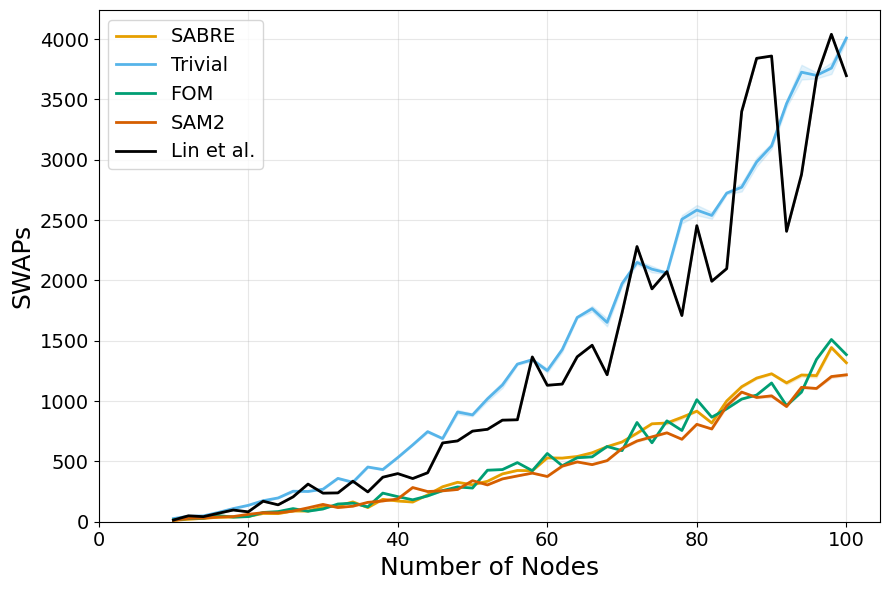

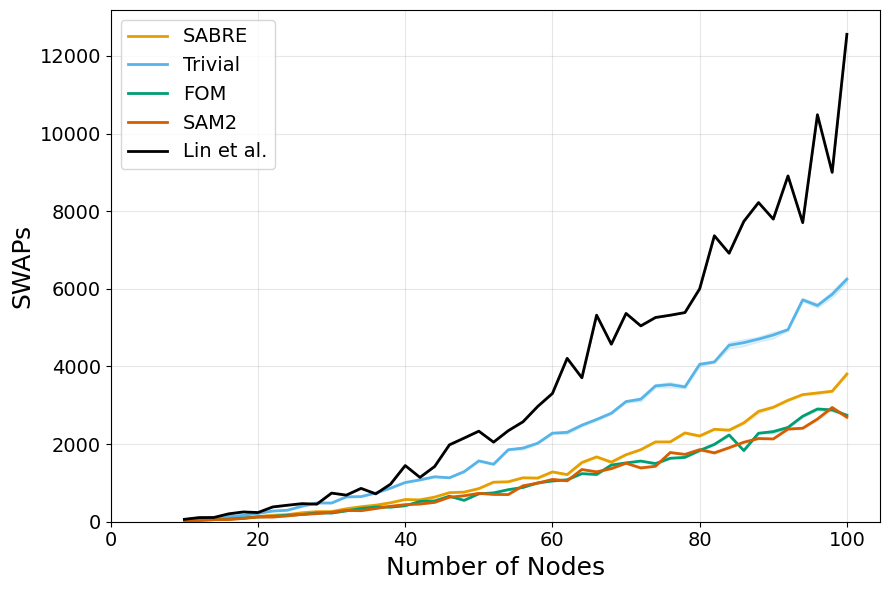

Barab?si?Albert graphs on extracted LNN paths


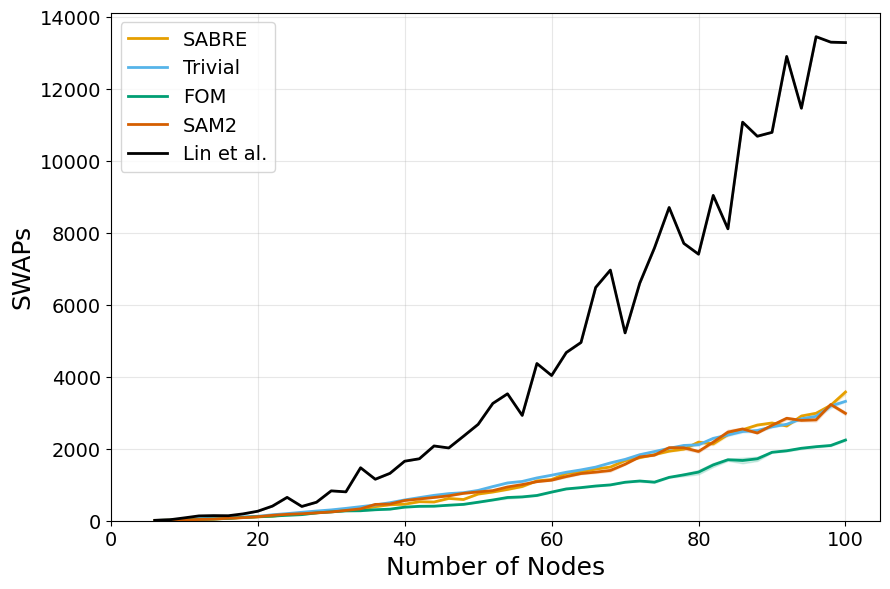

In [67]:
for graph_name, results, nodes, params in [
    ('Random regular graphs on extracted LNN paths', lnn_results_reg, nodes_reg, params_reg),
    ('Barab?si?Albert graphs on extracted LNN paths', lnn_results_ba, nodes_ba, params_ba),
]:
    print(graph_name)
    for metric, label in [
        ('swaps', 'SWAP count'),
        # ('two_qubit_gates', 'Optimized two-qubit gate count'),
        # ('circuit_depth', 'Optimized circuit depth'),
        # ('total_compilation_time', 'Total compilation time (seconds)'),
    ]:
        plot_metric_results(
            results, nodes, params,
            'quality' if metric in QUALITY_METRICS else 'times',
            metric, ylabel=label, title_prefix=graph_name,
        )


## Inspect one Lin et al. Fiedler ordering

The cell below follows the same basis-translated QAOA circuit and default Lin et al. parameters as the benchmark. It displays both the original input graph and the mapper's weighted interaction graph, prints the raw Fiedler order and the actual initial placement, and compares average edge spans with identity order. The actual initial placement can differ when the mapper applies its front-layer coupling correction.

Original input graph edges:


,u,v
0,0,15
1,0,23
2,0,37
3,1,2
4,1,4
5,1,12
6,2,7
7,2,36
8,3,4
9,3,18


Weighted mapper interaction graph edges:


,u,v,weight
0,0,15,0.301990
1,0,23,0.737280
2,0,37,0.471859
3,1,2,1.152000
4,1,4,0.471859
5,1,12,1.800000
6,2,7,0.471859
7,2,36,0.737280
8,3,4,0.301990
9,3,18,0.123695


Fiedler vector rows and sorted order:


,array_row,logical_qubit,fiedler_value,fiedler_position
18,18,18,-0.251988,0
3,3,3,-0.220167,1
39,39,39,-0.218659,2
4,4,4,-0.215120,3
1,1,1,-0.190248,4
12,12,12,-0.189109,5
2,2,2,-0.176241,6
19,19,19,-0.169067,7
7,7,7,-0.158656,8
36,36,36,-0.157505,9


Raw Fiedler order: [18, 3, 39, 4, 1, 12, 2, 19, 7, 36, 29, 5, 13, 34, 31, 35, 6, 38, 22, 16, 21, 30, 11, 17, 26, 32, 33, 28, 25, 9, 20, 24, 23, 37, 0, 15, 14, 10, 8, 27]
Actual Lin et al. initial order: [18, 3, 39, 4, 1, 12, 2, 19, 7, 36, 29, 5, 13, 34, 31, 35, 6, 38, 22, 16, 21, 30, 11, 17, 26, 32, 33, 28, 25, 9, 20, 24, 23, 37, 0, 15, 14, 10, 8, 27]
Second Laplacian eigenvalue: 0.03390338158065882
Connected components in interaction graph: 1


,graph,ordering,mean edge span
0,original input,identity,13.900000
1,original input,interaction-graph Fiedler,4.800000
2,weighted interaction,identity,15.239764
3,weighted interaction,raw Fiedler,2.485901
4,weighted interaction,actual initial placement,2.485901


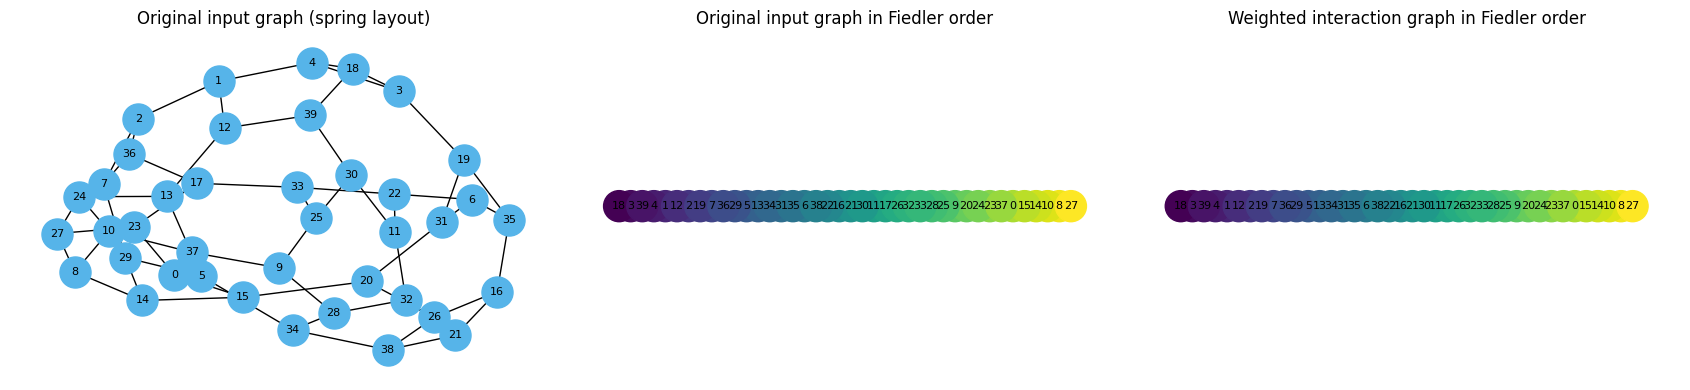

In [29]:
from scipy.linalg import eigh
from spectral_mapping_linetal import _interaction_graph, _fiedler_order

# Use the first configured random-regular instance; change these three values to inspect another case.
diagnostic_graph_type = 'reg'
diagnostic_param = params_reg[0]
diagnostic_n = nodes_reg[3]
diagnostic_graph = make_benchmark_graph(
    diagnostic_graph_type, diagnostic_n, diagnostic_param, seed=0
)
diagnostic_circuit = gen_qaoa_circuit(diagnostic_graph, reps=reps)
diagnostic_circuit = transpile(
    diagnostic_circuit,
    basis_gates=backend.basis_gates,
    seed_transpiler=0,
)

# Build the exact initial interaction graph consumed by the mapper after transpilation.
remaining_twoq = []
for instruction_index, instruction in enumerate(diagnostic_circuit.data):
    qargs = tuple(
        diagnostic_circuit.find_bit(qubit).index
        for qubit in instruction.qubits
    )
    if len(qargs) == 2 and instruction.operation.name != 'barrier':
        remaining_twoq.append((instruction_index, qargs[0], qargs[1]))

alpha, beta, tau = 0.8, 0.2, diagnostic_n
interaction_graph, forward, reverse, total_layers, front = _interaction_graph(
    diagnostic_n,
    remaining_twoq,
    current_order=None,
    alpha=alpha,
    beta=beta,
    tau=tau,
)
groups = [(logical,) for logical in range(diagnostic_n)]
group_order = _fiedler_order(interaction_graph, groups, current_order=None)
fiedler_order = [groups[group_index][0] for group_index in group_order]

# Recompute the vector with the same adjacency row order used by _fiedler_order,
# so each displayed vector row can be matched explicitly to its logical qubit.
logical_nodelist = list(range(diagnostic_n))
interaction_adjacency = nx.to_numpy_array(
    interaction_graph,
    nodelist=logical_nodelist,
    weight='weight',
    dtype=float,
)
interaction_laplacian = np.diag(interaction_adjacency.sum(axis=1)) - interaction_adjacency
if interaction_graph.number_of_edges():
    interaction_eigenvalues, interaction_eigenvectors = eigh(
        interaction_laplacian,
        check_finite=True,
    )
    fiedler_values = interaction_eigenvectors[:, 1]
else:
    # _fiedler_order falls back to identity when the interaction graph is edgeless.
    interaction_eigenvalues = np.zeros(diagnostic_n)
    fiedler_values = np.full(diagnostic_n, np.nan)
positions = {logical: pos for pos, logical in enumerate(fiedler_order)}

# Route once to show the placement after Lin et al.'s front-layer adjustment.
diagnostic_lnn_backend = LNNPathBackend(
    diagnostic_n,
    backend.basis_gates,
    lnn_hardware_paths[diagnostic_n],
)
diagnostic_result = route_circuit_on_heavyhex_path(
    diagnostic_circuit,
    diagnostic_lnn_backend,
    path=list(range(diagnostic_n)),
)
actual_initial_order = [None] * diagnostic_n
for logical, position in diagnostic_result.initial_layout.items():
    actual_initial_order[position] = logical

print('Original input graph edges:')
display(pd.DataFrame(
    sorted((int(u), int(v)) for u, v in diagnostic_graph.edges()),
    columns=['u', 'v'],
))
print('Weighted mapper interaction graph edges:')
display(pd.DataFrame(
    sorted(
        (int(u), int(v), float(attrs.get('weight', 1.0)))
        for u, v, attrs in interaction_graph.edges(data=True)
    ),
    columns=['u', 'v', 'weight'],
))
print('Fiedler vector rows and sorted order:')
display(pd.DataFrame([
    {
        'array_row': row,
        'logical_qubit': logical_nodelist[row],
        'fiedler_value': float(fiedler_values[row]),
        'fiedler_position': positions[logical_nodelist[row]],
    }
    for row in range(diagnostic_n)
]).sort_values('fiedler_position'))
print('Raw Fiedler order:', fiedler_order)
print('Actual Lin et al. initial order:', actual_initial_order)
print('Second Laplacian eigenvalue:', float(interaction_eigenvalues[1]) if diagnostic_n > 1 else float('nan'))
print('Connected components in interaction graph:', nx.number_connected_components(interaction_graph))


def average_edge_span(graph, order, weighted=False):
    position = {logical: rank for rank, logical in enumerate(order)}
    weighted_span = 0.0
    total_weight = 0.0
    spans = []
    for u, v, attrs in graph.edges(data=True):
        weight = float(attrs.get('weight', 1.0)) if weighted else 1.0
        span = abs(position[u] - position[v])
        spans.append(span)
        weighted_span += weight * span
        total_weight += weight
    return (weighted_span / total_weight) if total_weight else float('nan')


span_rows = [
    {
        'graph': 'original input',
        'ordering': 'identity',
        'mean edge span': average_edge_span(
            diagnostic_graph, list(range(diagnostic_n))
        ),
    },
    {
        'graph': 'original input',
        'ordering': 'interaction-graph Fiedler',
        'mean edge span': average_edge_span(diagnostic_graph, fiedler_order),
    },
    {
        'graph': 'weighted interaction',
        'ordering': 'identity',
        'mean edge span': average_edge_span(
            interaction_graph, list(range(diagnostic_n)), weighted=True
        ),
    },
    {
        'graph': 'weighted interaction',
        'ordering': 'raw Fiedler',
        'mean edge span': average_edge_span(
            interaction_graph, fiedler_order, weighted=True
        ),
    },
    {
        'graph': 'weighted interaction',
        'ordering': 'actual initial placement',
        'mean edge span': average_edge_span(
            interaction_graph, actual_initial_order, weighted=True
        ),
    },
]
display(pd.DataFrame(span_rows))

# Show the original graph in a topology-based layout, then both graphs in Fiedler order.
line_positions = {
    logical: (positions[logical], 0.0)
    for logical in range(diagnostic_n)
}
original_positions = nx.spring_layout(diagnostic_graph, seed=0)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
nx.draw_networkx(
    diagnostic_graph,
    pos=original_positions,
    ax=axes[0],
    node_color='#56B4E9',
    with_labels=True,
    node_size=500,
    font_size=8,
)
axes[0].set_title('Original input graph (spring layout)')
axes[0].axis('off')
nx.draw_networkx(
    diagnostic_graph,
    pos=line_positions,
    ax=axes[1],
    node_color=[positions[q] for q in range(diagnostic_n)],
    cmap='viridis',
    with_labels=True,
    node_size=500,
    font_size=8,
)
axes[1].set_title('Original input graph in Fiedler order')
axes[1].axis('off')
nx.draw_networkx(
    interaction_graph,
    pos=line_positions,
    ax=axes[2],
    node_color=[positions[q] for q in range(diagnostic_n)],
    edge_color=[interaction_graph[u][v].get('weight', 1.0)
                for u, v in interaction_graph.edges()],
    edge_cmap=plt.cm.plasma,
    with_labels=True,
    node_size=500,
    font_size=8,
    width=2,
)
axes[2].set_title('Weighted interaction graph in Fiedler order')
axes[2].axis('off')
fig.tight_layout()
plt.show()
